# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường
Đọc `README.md` và `GUIDE.md` trước.

**Cách chạy trên Colab:** Runtime → Change runtime type → **T4 GPU**, tạo Colab Secrets `KAGGLE_USERNAME`, `KAGGLE_KEY` (tuỳ chọn `HF_TOKEN`), rồi *Run all*.
Repo được clone vào Google Drive nên `work/` (adapter, dự đoán) và `report/` **sống sót khi mất session**: chạy lại *Run all*, mọi thí nghiệm đã xong sẽ được bỏ qua.
Dữ liệu ảnh để ở đĩa local `/content/data` (nhanh hơn Drive), sinh lại mỗi session (split cố định nên `dataset_version` không đổi).

**Cách chạy trên Kaggle** (khi hết quota Colab): New Notebook → File → Import Notebook (file này) → Settings: **Accelerator = GPU T4 x2**, **Internet = On** (cần xác minh SĐT) → **Add Input** dataset `lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes` (khỏi cần Kaggle key) → **Save Version → Save & Run All (Commit)**: chạy nền tới 12 giờ, tắt trình duyệt được. Xong thì tải `report.zip` (và `work/` nếu cần) ở tab **Output**.

## 0. Môi trường (Colab T4)

In [1]:
# Môi trường: Colab (repo trên Drive) hoặc Kaggle (repo trong /kaggle/working). Clone repo (chỉ lần đầu), chdir vào repo
import os, subprocess
REPO_URL = 'https://github.com/hdphuc127/K4-Track-4-Day10-VisionLanguageModel.git'
NAME = 'K4-Track-4-Day10-VisionLanguageModel'
ON_KAGGLE = os.path.exists('/kaggle/working')
if ON_KAGGLE:  # /kaggle/working thành Output khi Save Version; ảnh để /tmp cho khỏi chép vào Output
    REPO, DATA_DIR = f'/kaggle/working/{NAME}', '/tmp/data'
else:
    DATA_DIR = '/content/data'  # ảnh để đĩa local (nhanh hơn Drive)
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        REPO = f'/content/drive/MyDrive/{NAME}'
    except Exception as e:  # VS Code Colab extension có thể không mount được Drive
        print('KHÔNG mount được Drive (', e, ') -> dùng /content, mất session là mất work/')
        REPO = f'/content/{NAME}'
if not os.path.exists(REPO):
    subprocess.run(['git', 'clone', REPO_URL, REPO], check=True)
os.chdir(REPO)
if ON_KAGGLE:  # chạy tiếp: Add Input dataset chứa work/ của lần chạy trước -> thí nghiệm đã xong được bỏ qua
    import shutil
    from pathlib import Path
    src = Path('/kaggle/input')
    if z := next(src.rglob('work.zip'), None):  # phòng khi Kaggle không tự giải nén
        shutil.unpack_archive(z, '/tmp/prev'); src = Path('/tmp/prev')
    if prev := next(src.rglob('adapter_e1'), None):
        shutil.copytree(prev.parent, 'work', dirs_exist_ok=True)
        print('nạp lại work/ từ', prev.parent, ':', sorted(os.listdir('work')))
print('Kaggle' if ON_KAGGLE else 'Colab', os.getcwd())

Cloning into '/kaggle/working/K4-Track-4-Day10-VisionLanguageModel'...


nạp lại work/ từ /kaggle/input/lab-day10-prev-work/work : ['adapter_e1', 'adapter_e2', 'e0.jsonl', 'e0_as_pixel.json', 'e1.jsonl', 'e2.jsonl']
Kaggle /kaggle/working/K4-Track-4-Day10-VisionLanguageModel


In [2]:
# Runtime → Change runtime type → T4 GPU
import torch
assert torch.cuda.is_available(), 'Runtime KHÔNG có GPU: chọn lại kernel Colab với GPU T4 (xem hướng dẫn) rồi chạy lại từ đầu'
!nvidia-smi -L
!pip -q install -r requirements-colab.txt
# peft gắn LoRA vào nn.Linear thường (ViT, E3) sẽ kiểm tra torchao: bản cũ có sẵn (Kaggle 0.10) -> ImportError. Lab không dùng torchao.
!pip uninstall -y -q torchao
!python -m pytest -q

GPU 0: Tesla T4 (UUID: GPU-c679c394-4347-3d44-d0b1-7e0e6a8c291c)
GPU 1: Tesla T4 (UUID: GPU-8e83af74-9fcf-846a-ee48-317ab9fb0bfd)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 95.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 31.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 889.0/889.0 kB 21.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 48.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 23.7 MB/s eta 0:00:00
...........................s.........................................    [100%]
68 passed, 1 skipped in 0.43s


In [3]:
# Secrets: Colab Secrets / Kaggle Add-ons → Secrets. KHÔNG viết khoá vào notebook.
# Trên Kaggle nên Add Input dataset lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes -> khỏi cần KAGGLE_KEY.
from getpass import getpass
def secret(name, optional=False):
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        pass
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret(name)
    except Exception:
        pass
    return None if optional else getpass(f'{name}: ')  # VS Code extension: nhập tay (không lưu vào notebook)
for k, optional in (('KAGGLE_USERNAME', ON_KAGGLE), ('KAGGLE_KEY', ON_KAGGLE), ('HF_TOKEN', True)):
    if v := secret(k, optional):  # Kaggle "Save & Run All" không nhập tay được -> không bao giờ getpass
        os.environ[k] = v

## 1. Dữ liệu: tải và chia split

In [4]:
# Ảnh để local cho nhanh; chép splits/ (nhỏ) vào data/ của repo để check_submission đối chiếu meta.json
import shutil
from pathlib import Path
if not os.path.exists(f'{DATA_DIR}/splits/meta.json'):
    src = next(Path('/kaggle/input').rglob('labels-YOLO'), None) if ON_KAGGLE else None
    if src:  # dataset đã Add Input trên Kaggle
        !python scripts/prepare_data.py --source {src.parent} --out {DATA_DIR} --work /tmp/kaggle_raw
    else:
        !python scripts/prepare_data.py --kaggle --out {DATA_DIR} --work /tmp/kaggle_raw
shutil.copytree(f'{DATA_DIR}/splits', 'data/splits', dirs_exist_ok=True)

dataset_version : d10-21e4070301
  train  1422 ảnh  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}
  val     276 ảnh  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}
  test    311 ảnh  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}


'data/splits'

dataset_version: d10-21e4070301
train 1422 ảnh   13 phiên  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}  ảnh rỗng=0
val    276 ảnh    2 phiên  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}  ảnh rỗng=0
test   311 ảnh    3 phiên  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}  ảnh rỗng=0
OK: không session nào nằm ở hai split


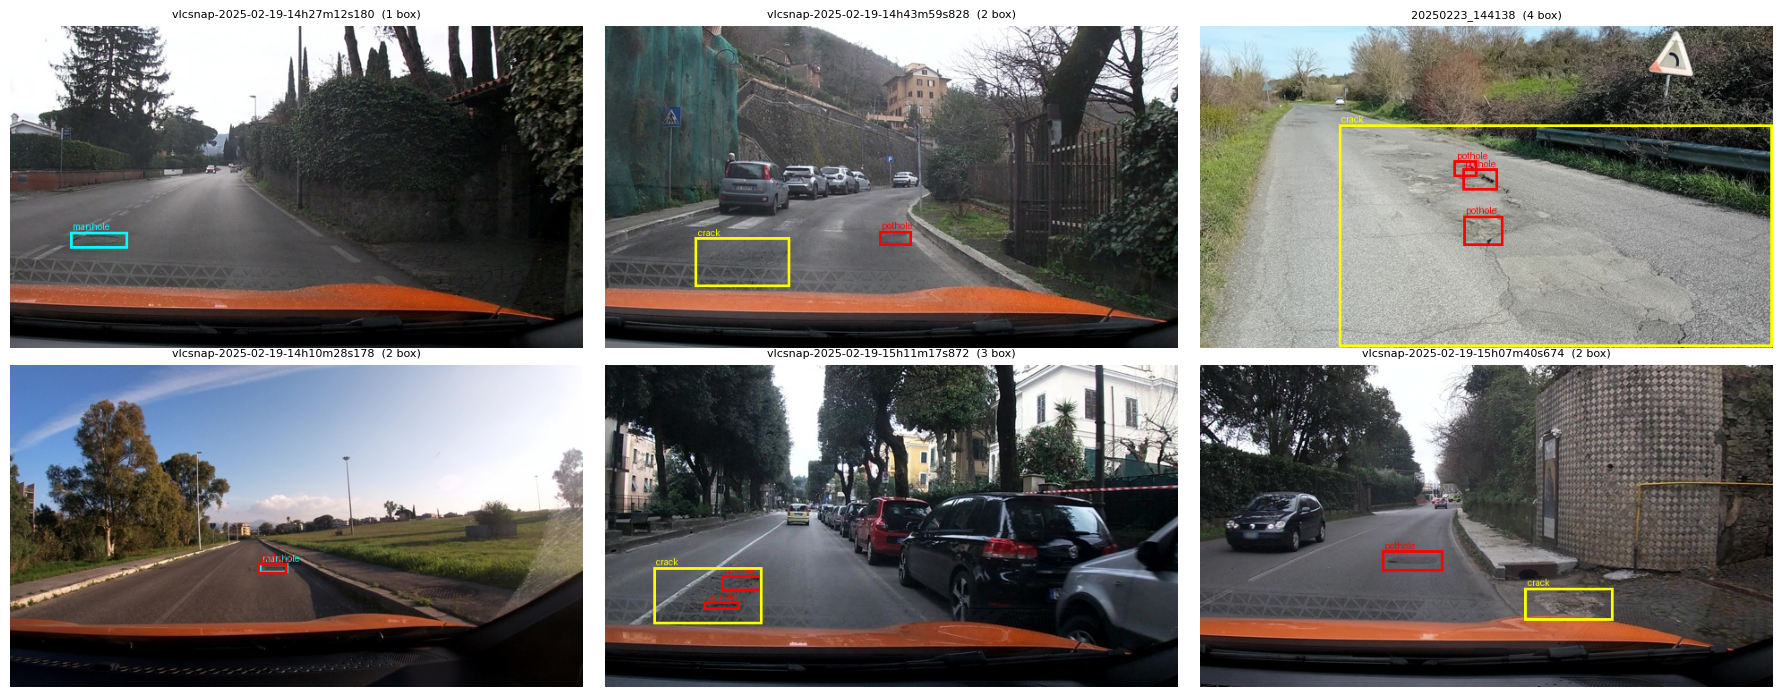

In [5]:
import json, random, re, gc, time, math
from pathlib import Path
import torch
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
from scripts.labcommon import CLASSES, read_jsonl, write_jsonl

DATA = Path(DATA_DIR); SPLITS = DATA / 'splits'
WORK = Path('work'); WORK.mkdir(exist_ok=True)
EVID = Path('report/evidence'); EVID.mkdir(parents=True, exist_ok=True)
FIG = Path('report/figures'); FIG.mkdir(parents=True, exist_ok=True)

rows = {s: read_jsonl(SPLITS / f'{s}.jsonl') for s in ('train', 'val', 'test')}
meta = json.loads((SPLITS / 'meta.json').read_text())
print('dataset_version:', meta['dataset_version'])
for s, rs in rows.items():
    box = {c: sum(o['label'] == c for r in rs for o in r['objects']) for c in CLASSES}
    print(f"{s:5s} {len(rs):4d} ảnh  {len({r['session'] for r in rs}):3d} phiên  boxes={box}  "
          f"ảnh rỗng={sum(not r['objects'] for r in rs)}")
sess = {s: {r['session'] for r in rs} for s, rs in rows.items()}
assert not (sess['train'] & sess['val'] or sess['train'] & sess['test'] or sess['val'] & sess['test']), 'session leak!'
print('OK: không session nào nằm ở hai split')

COLORS = {'pothole': 'red', 'crack': 'yellow', 'manhole': 'cyan'}
def load_img(r):
    return Image.open(DATA / r['image_path']).convert('RGB')

def draw(img, boxes, color=None, width=3):
    # boxes: [(label, (x1,y1,x2,y2) pixel)]
    d = ImageDraw.Draw(img)
    for lab, (x1, y1, x2, y2) in boxes:
        d.rectangle([x1, y1, x2, y2], outline=color or COLORS.get(lab, 'white'), width=width)
        d.text((x1 + 3, max(0, y1 - 12)), lab, fill=color or COLORS.get(lab, 'white'))
    return img

def yolo_px(o, W, H):
    xc, yc, w, h = o['yolo']
    return (o['label'], ((xc - w/2) * W, (yc - h/2) * H, (xc + w/2) * W, (yc + h/2) * H))

fig, axs = plt.subplots(2, 3, figsize=(18, 7))
for ax, r in zip(axs.flat, random.Random(0).sample([r for r in rows['train'] if r['objects']], 6)):
    ax.imshow(draw(load_img(r), [yolo_px(o, r['width'], r['height']) for o in r['objects']]))
    ax.set_title(f"{r['image_id']}  ({len(r['objects'])} box)", fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()

## 2. Nhãn: YOLO → JSON thang 0–1000

[{"label":"crack","bbox_2d":[269,453,628,1000]},{"label":"crack","bbox_2d":[108,458,628,986]},{"label":"pothole","bbox_2d":[480,472,544,533]},{"label":"pothole","bbox_2d":[384,489,431,544]},{"label":"pothole","bbox_2d":[566,492,617,536]},{"label":"pothole","bbox_2d":[289,508,344,569]},{"label":"pothole","bbox_2d":[433,533,505,589]},{"label":"pothole","bbox_2d":[214,564,380,683]},{"label":"pothole","bbox_2d":[588,611,633,678]},{"label":"pothole","bbox_2d":[359,617,431,689]},{"label":"pothole","bbox_2d":[447,656,547,786]},{"label":"pothole","bbox_2d":[372,703,503,797]},{"label":"pothole","bbox_2d":[139,856,259,922]}]
OK: round-trip khớp


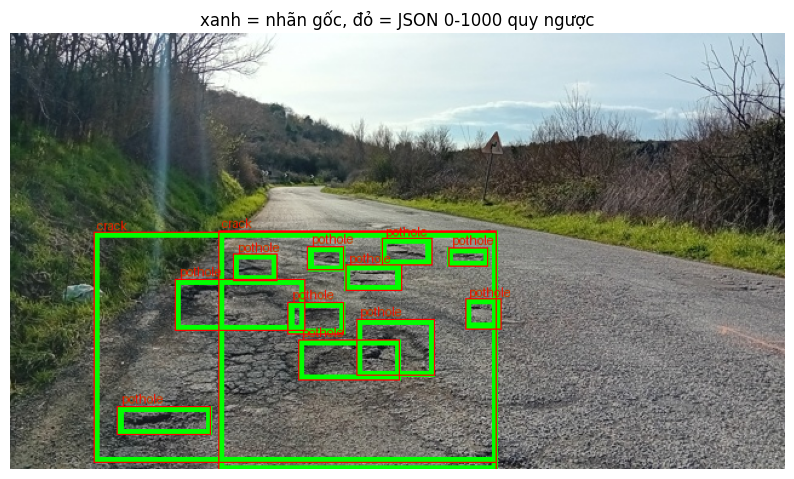

In [6]:
def yolo_to_box(label, yolo):
    xc, yc, w, h = yolo
    b = [(xc - w/2) * 1000, (yc - h/2) * 1000, (xc + w/2) * 1000, (yc + h/2) * 1000]
    return {'label': label, 'bbox_2d': [min(1000, max(0, round(v))) for v in b]}

def objects_to_answer(objects):
    boxes = sorted((yolo_to_box(o['label'], o['yolo']) for o in objects),
                   key=lambda b: (b['bbox_2d'][1], b['bbox_2d'][0]))  # trên→dưới, trái→phải
    return json.dumps(boxes, separators=(',', ':'))

PROMPT = ('Detect all road damage in this dashcam image. Classes: pothole, crack, manhole. '
          'Return ONLY a JSON list, no other text, in the form '
          '[{"label":"pothole","bbox_2d":[x1,y1,x2,y2]}]. '
          'Coordinates are integers on a 0-1000 scale relative to the image width and height '
          '(0,0 = top-left, 1000,1000 = bottom-right). Return [] if there is no damage.')

# Kiểm tra: JSON -> pixel phải trùng box gốc (sai số làm tròn <= 1 px)
r = max(rows['train'], key=lambda r: len(r['objects']))
ans = objects_to_answer(r['objects']); print(ans)
W, H = r['width'], r['height']
back = [(b['label'], (b['bbox_2d'][0]*W/1000, b['bbox_2d'][1]*H/1000, b['bbox_2d'][2]*W/1000, b['bbox_2d'][3]*H/1000))
        for b in json.loads(ans)]
orig = sorted((yolo_px(o, W, H) for o in r['objects']), key=lambda t: (t[1][1], t[1][0]))
for (l1, a), (l2, b) in zip(back, orig):
    b = (min(max(b[0], 0), W), min(max(b[1], 0), H), min(max(b[2], 0), W), min(max(b[3], 0), H))  # nhãn gốc có thể tràn khung, JSON đã kẹp về [0,1000]
    assert l1 == l2 and all(abs(x - y) <= 1.0 for x, y in zip(a, b)), (a, b)
print('OK: round-trip khớp')
img = draw(load_img(r), orig, color='lime', width=5); draw(img, back, color='red', width=1)
plt.figure(figsize=(10, 6)); plt.imshow(img); plt.title('xanh = nhãn gốc, đỏ = JSON 0-1000 quy ngược'); plt.axis('off'); plt.show()

## 3. E0: zero-shot

In [7]:
from transformers import (AutoConfig, AutoProcessor, BitsAndBytesConfig,
                          Qwen3VLForConditionalGeneration, get_cosine_schedule_with_warmup)
from peft import LoraConfig, PeftModel, get_peft_model

import yaml
CFG = {f'e{i}': yaml.safe_load(open(f'configs/e{i}.yaml', encoding='utf-8')) for i in range(5)}  # siêu tham số lấy từ đề
MODEL_ID = CFG['e0']['model_id']
MAX_NEW = CFG['e0']['max_new_tokens']
print(MODEL_ID, 'max_new_tokens =', MAX_NEW)
processor = AutoProcessor.from_pretrained(MODEL_ID)
processor.tokenizer.padding_side = 'left'

def load_base():
    q = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4',
                           bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True,
                           # transformers 5.x khớp tên theo prefix/đuôi, không theo chuỗi con: 'visual' một mình
                           # KHÔNG khớp 'model.visual.blocks...' -> ViT + projector bị nén 4-bit. Thêm 'model.visual'.
                           llm_int8_skip_modules=['visual', 'model.visual', 'lm_head'])
    model = Qwen3VLForConditionalGeneration.from_pretrained(
        MODEL_ID, quantization_config=q, dtype=torch.float16, device_map={'': 0})
    q4 = [n for n, m in model.named_modules() if 'visual' in n and type(m).__name__ == 'Linear4bit']
    assert not q4, f'ViT/projector bị lượng tử 4-bit ({len(q4)} module, vd {q4[:2]})'
    return model

def free():  # gọi sau khi đã `del model`
    gc.collect(); torch.cuda.empty_cache()

def user_msg(img, prompt=PROMPT):
    return {'role': 'user', 'content': [{'type': 'image', 'image': img}, {'type': 'text', 'text': prompt}]}

@torch.no_grad()
def predict(model, rs, out_path, bs=4):
    out_path = Path(out_path)
    if out_path.exists() and len(read_jsonl(out_path)) == len(rs):
        print('đã có', out_path); return
    model.eval(); res = []; t0 = time.time()
    for i in range(0, len(rs), bs):
        chunk = rs[i:i + bs]
        inputs = processor.apply_chat_template([[user_msg(load_img(r))] for r in chunk], tokenize=True,
                                               add_generation_prompt=True, return_dict=True,
                                               return_tensors='pt', padding=True).to(model.device)
        with torch.autocast('cuda', dtype=torch.float16):
            out = model.generate(**inputs, max_new_tokens=MAX_NEW, do_sample=False)
        texts = processor.batch_decode(out[:, inputs['input_ids'].shape[1]:], skip_special_tokens=True)
        res += [{'image_id': r['image_id'], 'raw': t} for r, t in zip(chunk, texts)]
        if i % 40 == 0:
            print(f'{i + len(chunk)}/{len(rs)}  {time.time() - t0:.0f}s')
    write_jsonl(out_path, res)
    print(f'xong {out_path}: {(time.time() - t0) / 60:.1f} phút')

if not Path('work/e0.jsonl').exists():
    model = load_base()
    print([n for n, _ in model.named_modules() if re.search(r'(layers\.0\.|blocks\.0\.|merger)', n)])
    predict(model, rows['test'], 'work/e0.jsonl')
    del model; free()

Qwen/Qwen3-VL-4B-Instruct max_new_tokens = 256


preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/5.50k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/10.9k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

In [8]:
!python scripts/score.py --pred work/e0.jsonl --name E0 --out report/evidence/e0.json --splits-dir {DATA_DIR}/splits
# Câu 3 (kiểm chứng): nếu coi output E0 là pixel thì sao? (ghi vào work/, KHÔNG phải evidence)
!python scripts/score.py --pred work/e0.jsonl --name E0_as_pixel --coord pixel --out work/e0_as_pixel.json --splits-dir {DATA_DIR}/splits

E0 [test] n=311 valid=0.961 P=0.119 R=0.065 F1=0.084 CI95=0.060-0.113 meanIoU=0.603 FP/img=0.90
   pothole  P=0.239 R=0.091 F1=0.132
   crack    P=0.034 R=0.023 F1=0.028
   manhole  P=0.290 R=0.123 F1=0.172
E0_as_pixel [test] n=311 valid=0.961 P=0.000 R=0.000 F1=0.000 CI95=0.000-0.000 meanIoU=0.000 FP/img=1.02
   pothole  P=0.000 R=0.000 F1=0.000
   crack    P=0.000 R=0.000 F1=0.000
   manhole  P=0.000 R=0.000 F1=0.000


In [9]:
# Câu 2: phân tích lỗi E0
from scripts.score import parse_output
e0 = read_jsonl('work/e0.jsonl'); gt = {r['image_id']: r for r in rows['test']}
parsed = [parse_output(p['raw']) for p in e0]
ok = [p for p in parsed if p is not None]
labs = [b['label'] for p in ok for b in p]
coords = [v for p in ok for b in p for v in b['bbox']]
print('parse_valid_rate      :', len(ok) / len(e0))
print('bọc ```json           :', sum('```' in p['raw'] for p in e0))
print('trả [] (không box)    :', sum(p == [] for p in ok), '/ GT ảnh rỗng:', sum(not r['objects'] for r in rows['test']))
print('box dự đoán / box GT  :', len(labs), '/', sum(len(r['objects']) for r in rows['test']))
print('nhãn ngoài 3 lớp      :', {l: labs.count(l) for l in set(labs) if l not in CLASSES})
print('nhãn theo lớp         :', {c: labs.count(c) for c in CLASSES})
print('max toạ độ            :', max(coords) if coords else None)
for p in e0[:5]:
    print('-' * 80, '\n', p['image_id'], 'GT:', objects_to_answer(gt[p['image_id']]['objects']), '\nRAW:', p['raw'][:400])
for p in [p for p, q in zip(e0, parsed) if q is None][:3]:
    print('=' * 80, '\nJSON HỎNG:', p['raw'][:400])

parse_valid_rate      : 0.9614147909967846
bọc ```json           : 0
trả [] (không box)    : 4 / GT ảnh rỗng: 0
box dự đoán / box GT  : 318 / 583
nhãn ngoài 3 lớp      : {}
nhãn theo lớp         : {'pothole': 46, 'crack': 203, 'manhole': 69}
max toạ độ            : 1000.0
-------------------------------------------------------------------------------- 
 vlcsnap-00200 GT: [{"label":"crack","bbox_2d":[352,642,534,728]},{"label":"manhole","bbox_2d":[894,756,1000,847]}] 
RAW: [{"label":"crack","bbox_2d": [759, 634, 850, 684]}]
-------------------------------------------------------------------------------- 
 vlcsnap-00201 GT: [{"label":"manhole","bbox_2d":[856,725,919,789]},{"label":"crack","bbox_2d":[558,736,731,825]}] 
RAW: [{"label":"crack","bbox_2d":[1, 470, 500, 500]}]
-------------------------------------------------------------------------------- 
 vlcsnap-00202 GT: [{"label":"manhole","bbox_2d":[275,672,405,722]}] 
RAW: [{"label":"manhole","bbox_2d": [309, 684, 399, 714]}]
--------

## 4. Dựng dữ liệu huấn luyện: chat template và mask loss

In [10]:
import torch.nn.functional as F
IMAGE_TOKEN_ID = processor.tokenizer.convert_tokens_to_ids('<|image_pad|>')
PAD = {'input_ids': processor.tokenizer.pad_token_id, 'attention_mask': 0, 'mm_token_type_ids': 0, 'labels': -100}

def encode_example(img, prompt, answer):
    u = user_msg(img, prompt)
    a = {'role': 'assistant', 'content': [{'type': 'text', 'text': answer}]}
    kw = dict(tokenize=True, return_dict=True, return_tensors='pt')
    p = processor.apply_chat_template([u], add_generation_prompt=True, **kw)
    f = dict(processor.apply_chat_template([u, a], add_generation_prompt=False, **kw))
    n = p['input_ids'].shape[1]
    assert torch.equal(f['input_ids'][0, :n], p['input_ids'][0]), 'prompt không phải tiền tố của chuỗi đầy đủ'
    f['labels'] = f['input_ids'].clone(); f['labels'][:, :n] = -100  # chỉ học phần trả lời
    return f

def collate(batch):
    extra = set(batch[0]) - set(PAD) - {'pixel_values', 'image_grid_thw'}
    assert not extra, f'key chưa xử lý: {extra}'
    L = max(b['input_ids'].shape[1] for b in batch)
    out = {k: torch.cat([F.pad(b[k], (0, L - b[k].shape[1]), value=v) for b in batch])  # pad phải khi train
           for k, v in PAD.items() if k in batch[0]}
    out['pixel_values'] = torch.cat([b['pixel_values'] for b in batch])  # nối, KHÔNG pad
    out['image_grid_thw'] = torch.cat([b['image_grid_thw'] for b in batch])
    return out

class TrainSet(torch.utils.data.Dataset):
    def __init__(self, rs): self.rs = rs
    def __len__(self): return len(self.rs)
    def __getitem__(self, i):
        r = self.rs[i]
        return encode_example(load_img(r), PROMPT, objects_to_answer(r['objects']))

# Kiểm tra
ex = TrainSet(rows['train'])[0]
print('keys:', list(ex), ' seq len:', ex['input_ids'].shape[1])
n_img = int((ex['input_ids'] == IMAGE_TOKEN_ID).sum()); print('token ảnh:', n_img); assert n_img == 220
ans_txt = processor.tokenizer.decode(ex['input_ids'][0][ex['labels'][0] != -100])
print('phần có loss:', repr(ans_txt))
assert ans_txt.startswith(objects_to_answer(rows['train'][0]['objects'])) and '<|im_end|>' in ans_txt
b = collate([TrainSet(rows['train'])[i] for i in range(2)])
print({k: tuple(v.shape) for k, v in b.items()})

keys: ['input_ids', 'attention_mask', 'mm_token_type_ids', 'pixel_values', 'image_grid_thw', 'labels']  seq len: 586
token ảnh: 220
phần có loss: '[{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]<|im_end|>\n'
{'input_ids': (2, 586), 'attention_mask': (2, 586), 'mm_token_type_ids': (2, 586), 'labels': (2, 586), 'pixel_values': (1760, 1536), 'image_grid_thw': (2, 3)}


## 5. Setup LoRA / đóng băng cho E1, E2, E3

In [11]:
LLM_RE = r'.*language_model\.layers\.\d+\.(self_attn\.(q|k|v|o)_proj|mlp\.(gate|up|down)_proj)'
VIT_RE = r'.*visual\.blocks\.\d+\.(attn\.(qkv|proj)|mlp\.linear_fc[12])'
PROJ_KEYS = ('visual.merger', 'visual.deepstack_merger_list')

def apply_setup(model, cfg):
    lora, vit = cfg['lora'], cfg['lora']['targets'] == 'llm+vit'
    for p in model.parameters():
        p.requires_grad = False
    model.enable_input_require_grads()
    pattern = f'({LLM_RE})|({VIT_RE})' if vit else LLM_RE
    matched = [n for n, _ in model.named_modules() if re.fullmatch(pattern, n)]
    assert len(matched) == (348 if vit else 252), len(matched)
    model = get_peft_model(model, LoraConfig(r=lora['r'], lora_alpha=lora['alpha'], lora_dropout=lora['dropout'],
                                             target_modules=pattern))
    if cfg['train_projector']:
        for n, p in model.named_parameters():
            if any(k in n for k in PROJ_KEYS):
                p.requires_grad = True
    # GradScaler cần master weight + grad fp32. Đổi dtype bằng `p.data = ...` (cả peft cũng làm vậy) để lại
    # grad_dtype=Half -> grad fp16 -> "Attempting to unscale FP16 gradients". Tạo Parameter mới cho sạch.
    for mod in model.modules():
        for pn, p in list(mod.named_parameters(recurse=False)):
            if p.requires_grad:
                setattr(mod, pn, torch.nn.Parameter(p.detach().float()))
    assert all(p.dtype == torch.float32 for p in model.parameters() if p.requires_grad)
    n_proj = sum(p.numel() for n, p in model.named_parameters() if p.requires_grad and 'lora_' not in n)
    assert n_proj == 0 or n_proj > 100e6, f'projector chỉ {n_proj:,} tham số (README: ≈109M) -> đang bị nén 4-bit?'
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"{cfg['name']}: {len(matched)} module LoRA, trainable = {n_train:,}")
    return model, n_train

In [12]:
# Câu 1: số tham số từng khối (đếm trên meta device, không tốn VRAM; model 4-bit đếm sai vì đóng gói)
from accelerate import init_empty_weights
with init_empty_weights():
    m = Qwen3VLForConditionalGeneration._from_config(AutoConfig.from_pretrained(MODEL_ID))
cnt = lambda mod: sum(p.numel() for p in mod.parameters())
v = m.model.visual
blocks = {'ViT (tổng)': cnt(v), '  visual.merger': cnt(v.merger),
          '  visual.deepstack_merger_list': cnt(v.deepstack_merger_list),
          '  ViT backbone (còn lại)': cnt(v) - cnt(v.merger) - cnt(v.deepstack_merger_list),
          'LLM (language_model, gồm embedding)': cnt(m.model.language_model),
          'lm_head': cnt(m.lm_head),
          'Tổng model': cnt(m)}
for k, val in blocks.items():
    print(f'{k:40s} {val / 1e6:10.1f} M')
print('lm_head tied với embedding:', m.lm_head.weight is m.model.language_model.embed_tokens.weight)
del m

ViT (tổng)                                    415.3 M
  visual.merger                                27.3 M
  visual.deepstack_merger_list                 81.8 M
  ViT backbone (còn lại)                      306.2 M
LLM (language_model, gồm embedding)          4022.5 M
lm_head                                       389.0 M
Tổng model                                   4826.8 M
lm_head tied với embedding: False


## 6. Vòng huấn luyện

In [13]:
def train(exp, cfg, train_rows):
    max_steps, lr, bs, accum, seed = (cfg[k] for k in ('max_steps', 'lr', 'batch_size', 'grad_accum', 'seed'))
    out = WORK / f'adapter_{exp}'
    if (out / 'run.json').exists():
        print('đã train', exp); return json.loads((out / 'run.json').read_text())
    random.seed(seed); torch.manual_seed(seed)
    model = load_base()
    model.config.use_cache = False
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant': False})
    model, n_train = apply_setup(model, cfg)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.0)
    sched = get_cosine_schedule_with_warmup(opt, int(0.05 * max_steps), max_steps)
    scaler = torch.amp.GradScaler('cuda')
    loader = torch.utils.data.DataLoader(TrainSet(train_rows), batch_size=bs, shuffle=True, drop_last=True,
                                         collate_fn=collate, num_workers=2,
                                         generator=torch.Generator().manual_seed(seed))
    def forever():
        while True:
            yield from loader
    it = forever()

    def save():
        model.save_pretrained(out)  # chỉ LoRA
        if cfg['train_projector']:  # projector KHÔNG nằm trong adapter -> lưu riêng
            torch.save({n: p.detach().cpu() for n, p in model.named_parameters()
                        if p.requires_grad and 'lora_' not in n}, out / 'projector.pt')

    torch.cuda.reset_peak_memory_stats(); t0 = time.time(); losses = []
    model.train()
    for step in range(1, max_steps + 1):
        tot = 0.0
        for _ in range(accum):
            batch = {k: v.to('cuda') for k, v in next(it).items()}
            with torch.autocast('cuda', dtype=torch.float16):
                loss = model(**batch).loss / accum
            if not torch.isfinite(loss):
                raise RuntimeError(f'loss không hữu hạn ở step {step} (tràn fp16?)')
            scaler.scale(loss).backward(); tot += loss.item()
        scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(params, 1.0)
        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()
        losses.append(tot)
        if step % 10 == 0:
            print(f'[{exp}] step {step}/{max_steps} loss={sum(losses[-10:]) / 10:.4f} '
                  f'lr={sched.get_last_lr()[0]:.2e} {(time.time() - t0) / 60:.1f} phút')
        if step % 100 == 0:
            save()
    # ponytail: không resume giữa chừng; mất session thì train lại thí nghiệm đó từ đầu
    run = {'exp': exp, 'setup': cfg['name'], 'lora': cfg['lora'], 'train_images': len(train_rows),
           'trainable_params': n_train, 'peak_vram_gb': round(torch.cuda.max_memory_allocated() / 1e9, 2),
           'train_minutes': round((time.time() - t0) / 60, 1), 'losses': losses}
    (out / 'run.json').write_text(json.dumps(run))
    print({k: v for k, v in run.items() if k != 'losses'})
    return run  # model/opt giải phóng khi hàm trả về; caller gọi free()

## 7. Suy luận và chấm E1–E3

In [14]:
def load_trained(exp):
    out = WORK / f'adapter_{exp}'
    model = PeftModel.from_pretrained(load_base(), out)
    if (out / 'projector.pt').exists():  # nạp lại projector đã train (copy_ ép về fp16)
        params = dict(model.named_parameters())
        sd = torch.load(out / 'projector.pt')
        for k, val in sd.items():
            params[k].data.copy_(val)
        print('nạp projector:', len(sd), 'tensor')
    return model

def score(pred, name, out, run=None, coord='norm1000'):
    cmd = ['python', 'scripts/score.py', '--pred', str(pred), '--name', name, '--out', str(out),
           '--splits-dir', str(SPLITS), '--coord', coord]
    for k in ('trainable_params', 'peak_vram_gb', 'train_minutes') if run else ():
        cmd += ['--meta', f'{k}={run[k]}']
    r = subprocess.run(cmd, capture_output=True, text=True)
    print(r.stdout, r.stderr); r.check_returncode()

def run_exp(exp, cfg, train_rows, evid_name=None):
    run = train(exp, cfg, train_rows); free()
    pred = WORK / f'{exp}.jsonl'
    if not (pred.exists() and len(read_jsonl(pred)) == len(rows['test'])):
        model = load_trained(exp); predict(model, rows['test'], pred); del model; free()
    score(pred, evid_name or exp.upper(), EVID / f'{exp}.json', run)
    return run

runs = {}
for exp in ('e1', 'e2', 'e3'):
    runs[exp] = run_exp(exp, CFG[exp], rows['train'])

đã train e1
E1 [test] n=311 valid=0.994 P=0.286 R=0.254 F1=0.269 CI95=0.231-0.308 meanIoU=0.677 FP/img=1.19
   pothole  P=0.193 R=0.132 F1=0.157
   crack    P=0.195 R=0.224 F1=0.208
   manhole  P=0.722 R=0.399 F1=0.514
 
đã train e2
E2 [test] n=311 valid=1.000 P=0.362 R=0.316 F1=0.337 CI95=0.297-0.382 meanIoU=0.680 FP/img=1.04
   pothole  P=0.171 R=0.157 F1=0.164
   crack    P=0.288 R=0.278 F1=0.283
   manhole  P=0.752 R=0.503 F1=0.603
 


model.safetensors.index.json:   0%|          | 0.00/64.7k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

...

244/311  679s


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transform

284/311  809s


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


xong work/e3.jsonl: 14.6 phút
E3 [test] n=311 valid=0.994 P=0.445 R=0.377 F1=0.409 CI95=0.366-0.453 meanIoU=0.708 FP/img=0.88
   pothole  P=0.319 R=0.248 F1=0.279
   crack    P=0.335 R=0.318 F1=0.326
   manhole  P=0.819 R=0.583 F1=0.681
 


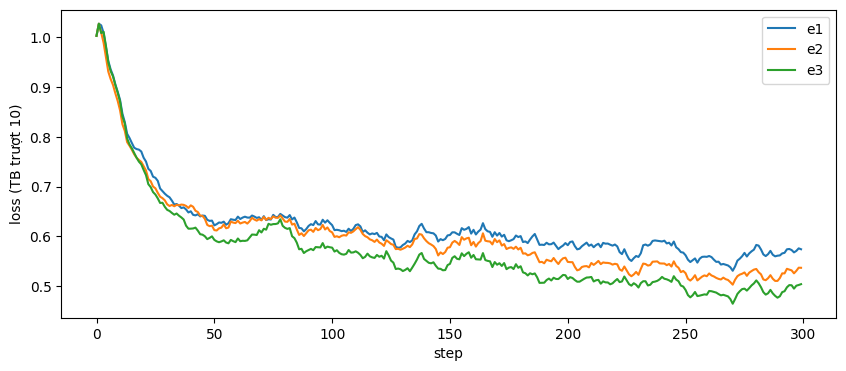

E1_as_pixel [test] n=311 valid=0.994 P=0.000 R=0.000 F1=0.000 CI95=0.000-0.000 meanIoU=0.000 FP/img=1.66
   pothole  P=0.000 R=0.000 F1=0.000
   crack    P=0.000 R=0.000 F1=0.000
   manhole  P=0.000 R=0.000 F1=0.000
 


In [15]:
# Loss curves + Câu 3: chấm output E1 như thể là pixel (ghi vào work/, không phải evidence)
plt.figure(figsize=(10, 4))
for exp, run in runs.items():
    l = run['losses']; plt.plot([sum(l[max(0, i - 9):i + 1]) / len(l[max(0, i - 9):i + 1]) for i in range(len(l))], label=exp)
plt.xlabel('step'); plt.ylabel('loss (TB trượt 10)'); plt.legend(); plt.savefig(FIG / 'loss.png', dpi=100); plt.show()
score(WORK / 'e1.jsonl', 'E1_as_pixel', WORK / 'e1_as_pixel.json', coord='pixel')

## 8. E4 (ablation tự chọn) và E5 (tuỳ chọn, GRPO)

In [16]:
# E4: biến data_size, giữ nguyên setup tốt nhất của E1–E3. Giá trị 1.0 chính là setup gốc (chấm lại cùng dự đoán).
f1 = {e: json.loads((EVID / f'{e}.json').read_text())['micro']['f1'] for e in ('e1', 'e2', 'e3')}
best = max(f1, key=f1.get); print('F1:', f1, '-> best =', best)
lo, hi = CFG['e4']['options']['data_size']['values']  # [0.1, 1.0]
sub = random.Random(CFG[best]['seed']).sample(rows['train'], round(lo * len(rows['train'])))
run_exp(f'e4_data_size_{lo}', CFG[best], sub, evid_name=f'E4_data_size_{lo}')
score(WORK / f'{best}.jsonl', f'E4_data_size_{hi}', EVID / f'e4_data_size_{hi}.json',
      json.loads((WORK / f'adapter_{best}' / 'run.json').read_text()))
# E5 (GRPO, tuỳ chọn): chưa làm.

F1: {'e1': 0.2690909090909091, 'e2': 0.33730522456461964, 'e3': 0.4085422469823584} -> best = e3


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

E3: 348 module LoRA, trainable = 148,426,752
[e4_data_size_0.1] step 10/300 loss=0.8976 lr=1.33e-04 1.6 phút
[e4_data_size_0.1] step 20/300 loss=0.7197 lr=2.00e-04 3.3 phút
[e4_data_size_0.1] step 30/300 loss=0.6083 lr=1.99e-04 4.9 phút
[e4_data_size_0.1] step 40/300 loss=0.5833 lr=1.96e-04 6.6 phút
[e4_data_size_0.1] step 50/300 loss=0.5369 lr=1.93e-04 8.2 phút
[e4_data_size_0.1] step 60/300 loss=0.5019 lr=1.88e-04 9.9 phút
[e4_data_size_0.1] step 70/300 loss=0.4801 lr=1.82e-04 11.5 phút
[e4_data_size_0.1] step 80/300 loss=0.4462 lr=1.75e-04 13.2 phút
[e4_data_size_0.1] step 90/300 loss=0.4389 lr=1.68e-04 14.9 phút
[e4_data_size_0.1] step 100/300 loss=0.4080 lr=1.59e-04 16.5 phút
[e4_data_size_0.1] step 110/300 loss=0.3917 lr=1.50e-04 18.2 phút
[e4_data_size_0.1] step 120/300 loss=0.3437 lr=1.40e-04 19.8 phút
[e4_data_size_0.1] step 130/300 loss=0.3498 lr=1.30e-04 21.5 phút
[e4_data_size_0.1] step 140/300 loss=0.3473 lr=1.19e-04 23.1 phút
[e4_data_size_0.1] step 150/300 loss=0.3040 lr

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


...

244/311  908s


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transform

284/311  1075s


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


xong work/e4_data_size_0.1.jsonl: 19.6 phút
E4_data_size_0.1 [test] n=311 valid=1.000 P=0.260 R=0.307 F1=0.281 CI95=0.247-0.318 meanIoU=0.673 FP/img=1.64
   pothole  P=0.160 R=0.198 F1=0.177
   crack    P=0.176 R=0.244 F1=0.205
   manhole  P=0.656 R=0.503 F1=0.569
 
E4_data_size_1.0 [test] n=311 valid=0.994 P=0.445 R=0.377 F1=0.409 CI95=0.366-0.453 meanIoU=0.708 FP/img=0.88
   pothole  P=0.319 R=0.248 F1=0.279
   crack    P=0.335 R=0.318 F1=0.326
   manhole  P=0.819 R=0.583 F1=0.681
 


## Báo cáo: bảng tổng hợp + ảnh minh hoạ

In [17]:
# Bảng tổng hợp để dán vào REPORT.md
SETUP_NAME = {'e0': 'zero-shot', 'e1': 'LoRA LLM', 'e2': '+ projector', 'e3': '+ LoRA ViT',
              'e4_data_size_0.1': f'data_size=0.1 ({best.upper()})', 'e4_data_size_1.0': f'data_size=1.0 ({best.upper()})'}
print('| Mã | Setup | Tham số huấn luyện | VRAM đỉnh (GB) | Phút | F1 | CI95 | FP/ảnh | F1 pothole | F1 crack | F1 manhole | valid |')
print('|---|---|---|---|---|---|---|---|---|---|---|---|')
for e, name in SETUP_NAME.items():
    d = json.loads((EVID / f'{e}.json').read_text()); mt = d['meta']; pc = d['per_class']
    print(f"| {d['name']} | {name} | {mt.get('trainable_params', 0):,} | {mt.get('peak_vram_gb', '')} | "
          f"{mt.get('train_minutes', '')} | {d['micro']['f1']:.3f} | {d['f1_ci95'][0]:.3f}–{d['f1_ci95'][1]:.3f} | "
          f"{d['fp_per_image']:.2f} | {pc['pothole']['f1']:.3f} | {pc['crack']['f1']:.3f} | {pc['manhole']['f1']:.3f} | "
          f"{d['parse_valid_rate']:.3f} |")
print('dataset_version:', meta['dataset_version'])

| Mã | Setup | Tham số huấn luyện | VRAM đỉnh (GB) | Phút | F1 | CI95 | FP/ảnh | F1 pothole | F1 crack | F1 manhole | valid |
|---|---|---|---|---|---|---|---|---|---|---|---|
| E0 | zero-shot | 0 |  |  | 0.084 | 0.060–0.113 | 0.90 | 0.132 | 0.028 | 0.172 | 0.961 |
| E1 | LoRA LLM | 33,030,144 | 6.91 | 44.6 | 0.269 | 0.231–0.308 | 1.19 | 0.157 | 0.208 | 0.514 | 0.994 |
| E2 | + projector | 142,135,296 | 8.73 | 45.2 | 0.337 | 0.297–0.382 | 1.04 | 0.164 | 0.283 | 0.603 | 1.000 |
| E3 | + LoRA ViT | 148,426,752 | 8.92 | 49.8 | 0.409 | 0.366–0.453 | 0.88 | 0.279 | 0.326 | 0.681 | 0.994 |
| E4_data_size_0.1 | data_size=0.1 (E3) | 148,426,752 | 8.33 | 49.6 | 0.281 | 0.247–0.318 | 1.64 | 0.177 | 0.205 | 0.569 | 1.000 |
| E4_data_size_1.0 | data_size=1.0 (E3) | 148,426,752 | 8.92 | 49.8 | 0.409 | 0.366–0.453 | 0.88 | 0.279 | 0.326 | 0.681 | 0.994 |
dataset_version: d10-21e4070301


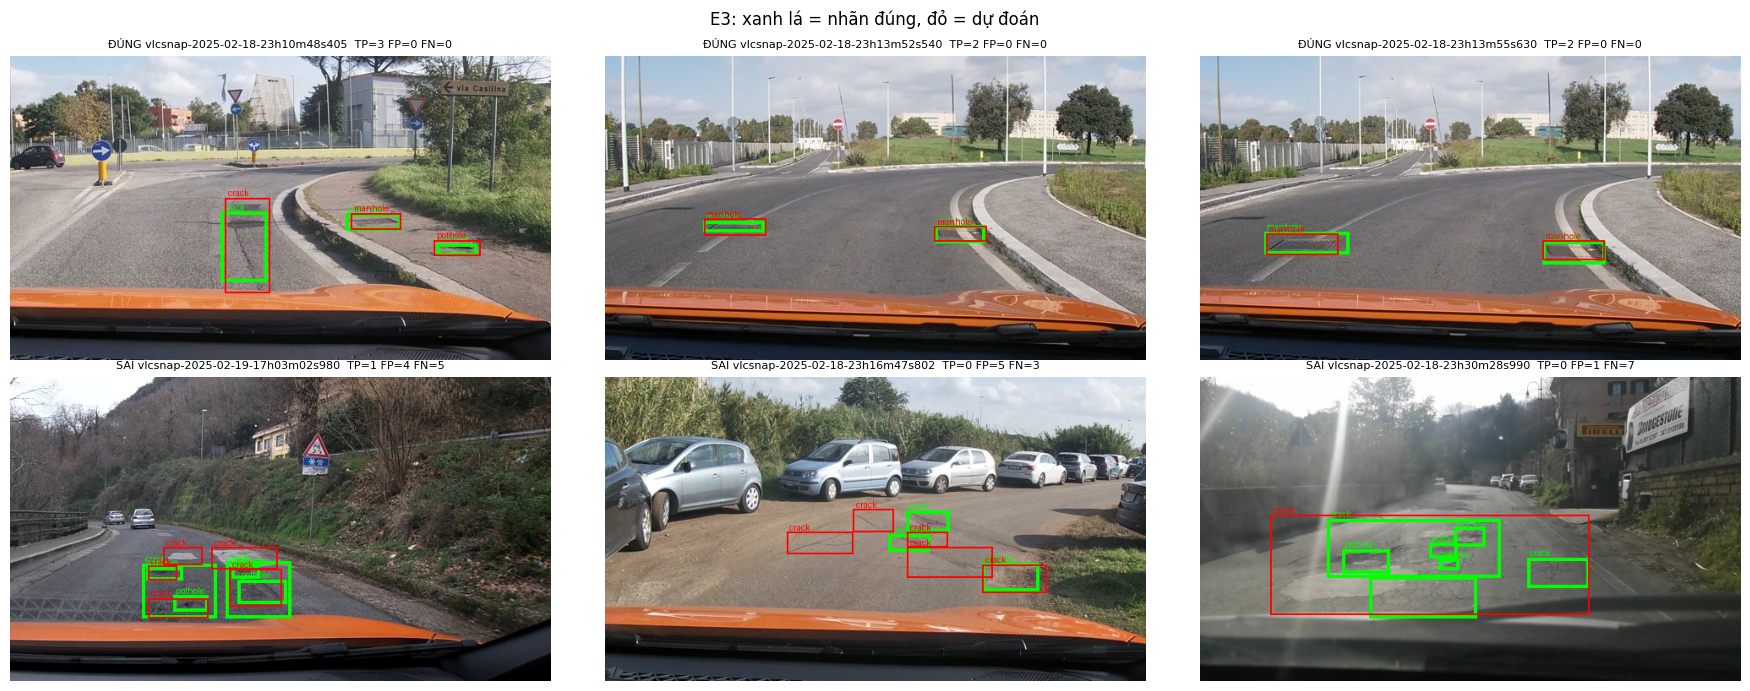

In [18]:
# >= 6 ảnh đúng/sai của setup tốt nhất: xanh lá = GT, đỏ = dự đoán
from scripts.score import _gt_boxes, _match
preds = {p['image_id']: parse_output(p['raw']) for p in read_jsonl(WORK / f'{best}.jsonl')}
def img_stats(r):
    per, _ = _match(_gt_boxes(r), preds[r['image_id']] or [])
    return [sum(v[k] for v in per.values()) for k in range(3)]  # tp, fp, fn
scored = [(r, *img_stats(r)) for r in rows['test'] if r['objects']]
good = sorted(scored, key=lambda t: (t[2] + t[3], -t[1]))[:3]
bad = sorted(scored, key=lambda t: -(t[2] + t[3]))[:3]
fig, axs = plt.subplots(2, 3, figsize=(18, 7))
for ax, (r, tp, fp, fn), tag in zip(axs.flat, good + bad, ['ĐÚNG'] * 3 + ['SAI'] * 3):
    W, H = r['width'], r['height']
    img = draw(load_img(r), [yolo_px(o, W, H) for o in r['objects']], color='lime', width=4)
    pb = [(p['label'], (p['bbox'][0] * W / 1000, p['bbox'][1] * H / 1000, p['bbox'][2] * W / 1000, p['bbox'][3] * H / 1000))
          for p in preds[r['image_id']] or []]
    draw(img, pb, color='red', width=2)
    img.save(FIG / f"{best}_{tag}_{r['image_id']}.jpg")
    ax.imshow(img); ax.set_title(f"{tag} {r['image_id']}  TP={tp} FP={fp} FN={fn}", fontsize=8); ax.axis('off')
plt.suptitle(f'{best.upper()}: xanh lá = nhãn đúng, đỏ = dự đoán'); plt.tight_layout()
plt.savefig(FIG / f'{best}_examples.png', dpi=100); plt.show()

In [19]:
!python scripts/check_submission.py
# Tải report/ về máy để commit. Kaggle: lấy report.zip ở tab Output; Colab: tải trực tiếp (hoặc dùng thư mục trên Drive)
!zip -qr ../report.zip report
if not ON_KAGGLE:
    from google.colab import files; files.download('../report.zip')

[PASS] evidence e0
[PASS] evidence e1
[PASS] evidence e2
[PASS] evidence e3
[PASS] evidence e4 — 2 file
[PASS] e1 meta
[PASS] e2 meta
[PASS] e3 meta
[PASS] dataset_version nhất quán — ['d10-21e4070301']
[PASS] khớp data/splits/meta.json
[FAIL] REPORT.md đã điền — còn chuỗi '<điền'
[PASS] git commits — 6/5
[PASS] git forbidden files

1 FAIL, 0 WARN
